## 1. Setup: Libraries and Settings


In [1]:
import os, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# ── CONFIG ────────────────────────────────────────────────
DATA_PATH = "/scratch1/e21-4yp-mcformer/All_Stations (1).xlsx"
# Upstream stations only — Glencource is the TARGET, not an input
UPSTREAM  = ["Kithulgala", "Norwood", "Deraniyagala"]
TARGET_STATION = "Glencource" # RF_Glencource also used as input feature
STATIONS  = ["Hanwella ", "Kithulgala", "Norwood", "Glencource", "Deraniyagala"]  # keep for loading

# Increased from 168 (1 week) → 504 (21 days) based on EDA lag analysis
# which showed upstream Q correlates with Glencource up to 14+ days
LOOKBACK  = 504       # 504 hours = 21 days
FORECAST_HORIZON = 6
SEED = 7

# ── Reproducibility ───────────────────────────────────────
# These must be set BEFORE any model or layer is created
os.environ["PYTHONHASHSEED"]       = str(SEED)  # Python hash seed
os.environ["TF_DETERMINISTIC_OPS"] = "1"        # deterministic GPU ops
os.environ["TF_CUDNN_DETERMINISTIC"]= "1"       # deterministic cuDNN

def set_seed(s=SEED):
    random.seed(s)           # Python random
    np.random.seed(s)        # NumPy random
    tf.random.set_seed(s)    # TensorFlow random

set_seed()
print(f"Setup done. Seed={SEED}")

I0000 00:00:1793543544.062951 1970913 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793543544.063801 1970913 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793543544.121483 1970913 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793543545.349155 1970913 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them 

Setup done. Seed=7


## 2. Data Preperation


In [2]:
import openpyxl
wb = openpyxl.load_workbook(DATA_PATH, read_only=True)
print("Sheet names:", wb.sheetnames)
wb.close()

Sheet names: ['Hanwella ', 'Kithulgala', 'Norwood', 'Glencource', 'Deraniyagala']


In [3]:
for s in STATIONS:
    raw = pd.read_excel(DATA_PATH, sheet_name=s)
    print(f"{s}: {list(raw.columns)}")
    print(raw.head(2))
    print()

Hanwella : ['Year', 'Month', 'Day', 'Hour', 'Q', 'RF']
   Year  Month  Day  Hour          Q   RF
0  2020      1    1     1  35.481071  0.0
1  2020      1    1     2  36.477384  0.0

Kithulgala: ['Year', 'Month', 'Day', 'Hour', 'Q', 'RF']
   Year  Month  Day  Hour          Q   RF
0  2020      1    1     1  29.689662  0.0
1  2020      1    1     2  20.782184  0.0

Norwood: ['Year', 'Month', 'Day', 'Hour', 'Q', 'RF']
   Year  Month  Day  Hour         Q   RF
0  2020      1    1     1  4.451713  0.0
1  2020      1    1     2  4.451713  0.0

Glencource: ['Year', 'Month', 'Day', 'Hour', 'Q', 'RF']
   Year  Month  Day  Hour          Q   RF
0  2020      1    1     1  49.014397  0.0
1  2020      1    1     2  52.114062  0.0

Deraniyagala: ['Year', 'Month', 'Day', 'Hour', 'Q', 'RF']
   Year  Month  Day  Hour         Q   RF
0  2020      1    1     1  7.501950  0.0
1  2020      1    1     2  8.616324  0.0



## 3. Load Sri Lanka Station Data


In [4]:
def load_station(station):
    """Load one station sheet, fix timestamps, reindex to hourly grid."""
    raw = pd.read_excel(DATA_PATH, sheet_name=station)
    raw = raw[raw["Month"] != 0]          # drop invalid month=0 rows (Glencource has 288 of these)
    raw["Hour"] = raw["Hour"] - 1         # convert Hour 1..24 → 0..23
    raw["date"] = pd.to_datetime({
        "year":  raw["Year"],
        "month": raw["Month"],
        "day":   raw["Day"],
        "hour":  raw["Hour"]
    }, errors="coerce")
    raw = raw.dropna(subset=["date"])
    raw = raw.set_index("date").sort_index()
    # Average duplicate timestamps (keep clean)
    raw = raw[["Q", "RF"]].groupby(level=0).mean()
    # Reindex to a continuous hourly grid — missing hours become NaN (NOT zero)
    full_idx = pd.date_range(raw.index.min(), raw.index.max(), freq="h")
    raw = raw.reindex(full_idx)
    return raw

# ── Load all stations ──────────────────────────────────────────────────────
station_data = {}
for s in STATIONS:
    station_data[s] = load_station(s)
    print(f"{s}: {len(station_data[s])} hourly rows | "
          f"Q missing: {station_data[s]['Q'].isna().sum()} | "
          f"RF missing: {station_data[s]['RF'].isna().sum()}")

# ── Build the main modelling dataframe ────────────────────────────────────
# Features: RF and Q from the 3 upstream stations + latest Glencource Q
# Target:   Glencource Q (next 6 hour)
#
# WHY add Glencource_Q as a feature?
#   Autoregressive signal — the current discharge strongly predicts the next hour.
#   EDA showed this is the single highest-correlated feature.
parts = []
for s in UPSTREAM:
    parts.append(station_data[s][["RF", "Q"]].rename(
        columns={"RF": f"RF_{s}", "Q": f"Q_{s}"}
    ))

# Add Glencource RF as an input feature
parts.append(station_data[TARGET_STATION][["RF"]].rename(
    columns={"RF": "RF_Glencource"}
))

# Target column: Glencource discharge (this is what we predict)
parts.append(station_data[TARGET_STATION][["Q"]].shift(-FORECAST_HORIZON).rename(
    columns={"Q": "Q_Glencource_target"}
))

df = pd.concat(parts, axis=1).sort_index()

# Find common period where ALL stations overlap
common_start = max(station_data[s].index.min() for s in UPSTREAM + [TARGET_STATION])
common_end   = min(station_data[s].index.max() for s in UPSTREAM + [TARGET_STATION])
df = df.loc[common_start:common_end]

print(f"\nFinal df shape: {df.shape}")
print(f"Period: {df.index.min()} → {df.index.max()}")
print(f"Columns: {list(df.columns)}")

Hanwella : 43848 hourly rows | Q missing: 15 | RF missing: 0
Kithulgala: 43848 hourly rows | Q missing: 24 | RF missing: 24
Norwood: 43848 hourly rows | Q missing: 0 | RF missing: 0
Glencource: 43848 hourly rows | Q missing: 0 | RF missing: 0
Deraniyagala: 43848 hourly rows | Q missing: 4 | RF missing: 240

Final df shape: (43848, 8)
Period: 2020-01-01 00:00:00 → 2024-12-31 23:00:00
Columns: ['RF_Kithulgala', 'Q_Kithulgala', 'RF_Norwood', 'Q_Norwood', 'RF_Deraniyagala', 'Q_Deraniyagala', 'RF_Glencource', 'Q_Glencource_target']


In [5]:
# Apply gap-filling first so NaN hours are not misclassified as zero-rainfall days
# RF_Glencource included — same threshold applied consistently across all stations
rainfall_cols = [f"RF_{s}" for s in UPSTREAM] + ["RF_Glencource"]
for col in rainfall_cols:
    df[col] = df[col].ffill(limit=3)   # fill short gaps before threshold

# ── Method B: 10mm Daily Rainfall Threshold ───────────────────────────────
# The 10mm threshold is applied on DAILY aggregated rainfall.
# Hours belonging to a day where total rainfall < 10mm → set to 0.
# Hours belonging to a day where total rainfall >= 10mm → kept as-is.
# Applied to ALL rainfall inputs — upstream and local (RF_Glencource) —
# for consistency.

RAINFALL_THRESHOLD = 10.0  # mm/day

for col in rainfall_cols:
    daily_total = df[col].resample("D").transform("sum")
    mask = daily_total < RAINFALL_THRESHOLD
    original_count = mask.sum()
    df[col] = df[col].where(~mask, 0.0)
    print(f"{col}: {original_count} hourly rows zeroed "
          f"(belong to days with daily RF < 10mm)")

print(f"\nDataframe shape unchanged: {df.shape}")
print(f"Discharge NaN count: {df['Q_Glencource_target'].isna().sum()}")

RF_Kithulgala: 28272 hourly rows zeroed (belong to days with daily RF < 10mm)
RF_Norwood: 33336 hourly rows zeroed (belong to days with daily RF < 10mm)
RF_Deraniyagala: 29376 hourly rows zeroed (belong to days with daily RF < 10mm)
RF_Glencource: 30624 hourly rows zeroed (belong to days with daily RF < 10mm)

Dataframe shape unchanged: (43848, 8)
Discharge NaN count: 6


## 4. Train / Validation / Test Split


In [6]:
# BEFORE (current) — percentage split risks leakage across years
# n = len(df)
# i1, i2 = int(n * 0.70), int(n * 0.85)

# AFTER — chronological date split (matches EDA notebook convention)
# Train: 2020–2022 | Val: 2023 | Test: 2024
TRAIN_END = "2022-12-31 23:00"
VAL_END   = "2023-12-31 23:00"

train_df = df.loc[:TRAIN_END]
val_df   = df.loc[TRAIN_END:VAL_END].iloc[1:]   # iloc[1:] avoids overlap
test_df  = df.loc[VAL_END:].iloc[1:]

print(f"Train: {len(train_df)} hours ({len(train_df)//24} days)")
print(f"Val:   {len(val_df)} hours ({len(val_df)//24} days)")
print(f"Test:  {len(test_df)} hours ({len(test_df)//24} days)")

Train: 26304 hours (1096 days)
Val:   8760 hours (365 days)
Test:  8784 hours (366 days)


## 5. Scaling (MinMax)



In [7]:
# 7 features: RF + Q from 3 upstream stations, plus current Glencource Q
FEATURE_COLS = (
    [f"RF_{s}" for s in UPSTREAM] +    # 3 rainfall inputs
    ["RF_Glencource"] +                 # local rainfall at target station
    [f"Q_{s}"  for s in UPSTREAM]     # 3 upstream discharge inputs
)
TARGET_COL = ["Q_Glencource_target"]   # predict 6-HOUR-AHEAD Glencource discharge

# Fit scalers on TRAINING data ONLY (prevents data leakage)
from sklearn.preprocessing import MinMaxScaler
scaler_x = MinMaxScaler().fit(train_df[FEATURE_COLS])
scaler_y = MinMaxScaler().fit(train_df[TARGET_COL])

# Transform all splits using training statistics
train_x_scaled = scaler_x.transform(train_df[FEATURE_COLS])
train_y_scaled = scaler_y.transform(train_df[TARGET_COL]).ravel()

val_x_scaled   = scaler_x.transform(val_df[FEATURE_COLS])
val_y_scaled   = scaler_y.transform(val_df[TARGET_COL]).ravel()

test_x_scaled  = scaler_x.transform(test_df[FEATURE_COLS])
test_y_scaled  = scaler_y.transform(test_df[TARGET_COL]).ravel()

print(f"Features ({len(FEATURE_COLS)}): {FEATURE_COLS}")
print(f"Target: {TARGET_COL}")

Features (7): ['RF_Kithulgala', 'RF_Norwood', 'RF_Deraniyagala', 'RF_Glencource', 'Q_Kithulgala', 'Q_Norwood', 'Q_Deraniyagala']
Target: ['Q_Glencource_target']


## 6. Input Windows 


In [8]:
# AFTER — transform each split separately, then recombine
train_x = scaler_x.transform(train_df[FEATURE_COLS].ffill(limit=3).fillna(0))
val_x   = scaler_x.transform(val_df[FEATURE_COLS].ffill(limit=3).fillna(0))
test_x  = scaler_x.transform(test_df[FEATURE_COLS].ffill(limit=3).fillna(0))
train_y = scaler_y.transform(train_df[TARGET_COL].ffill(limit=3).fillna(0)).ravel()
val_y   = scaler_y.transform(val_df[TARGET_COL].ffill(limit=3).fillna(0)).ravel()
test_y  = scaler_y.transform(test_df[TARGET_COL].ffill(limit=3).fillna(0)).ravel()

# Recombine for windowing (gap detection still needs the full array)
x_all = np.concatenate([train_x, val_x, test_x], axis=0)
y_all = np.concatenate([train_y, val_y, test_y], axis=0)

# Detect timestamp gaps
time_diff = df.index.to_series().diff()
is_gap    = time_diff > pd.Timedelta("1h")
gap_locs  = set(np.where(is_gap)[0])
print(f"Timestamp gap locations: {gap_locs}")

def windows_for(idx):
    """
    Build sliding windows.
    Skip any window that:
      1. Spans a timestamp gap (missing hours)
      2. Contains any NaN values in features or target
    """
    valid = []
    for i in idx:
        # Check 1: no timestamp gap in this window
        window_rows = set(range(i - LOOKBACK + 1, i + 1))
        if window_rows.intersection(gap_locs):
            continue

        # Check 2: no NaN in feature window
        x_win = x_all[i - LOOKBACK + 1 : i + 1]
        if not np.isfinite(x_win).all():
            continue

        # Check 3: target value must exist
        if not np.isfinite(y_all[i]):
            continue

        valid.append(i)

    valid = np.array(valid)
    if len(valid) == 0:
        return np.empty((0, LOOKBACK, len(FEATURE_COLS))), np.empty(0)

    X = np.stack([x_all[i - LOOKBACK + 1 : i + 1] for i in valid])
    y = y_all[valid]
    return X, y

# Index boundaries aligned to date split
i1 = df.index.get_loc(train_df.index[-1])
i2 = df.index.get_loc(val_df.index[-1])
n  = len(df)

tr_idx = np.arange(LOOKBACK - 1, i1)
va_idx = np.arange(i1, i2)
te_idx = np.arange(i2, n - FORECAST_HORIZON)

X_train, y_train = windows_for(tr_idx)
X_val,   y_val   = windows_for(va_idx)
X_test,  y_test  = windows_for(te_idx)

print(f"Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")
print(f"y_train - min:{y_train.min():.4f} max:{y_train.max():.4f}")
print(f"NaN in X_train: {np.isnan(X_train).sum()}")
print(f"NaN in y_train: {np.isnan(y_train).sum()}")

Timestamp gap locations: set()
Train: (25800, 504, 7) | Val: (8760, 504, 7) | Test: (8779, 504, 7)
y_train - min:0.0000 max:1.0000
NaN in X_train: 0
NaN in y_train: 0


## 7. Build and Train the LSTM


In [9]:
# IMPROVED model:
#   - Input shape now (504, 6) — 21 days, 6 features (removed Q_Glencource_input)
#   - Added Dropout(0.2) after second LSTM to reduce overfitting
#   - Kept two LSTM layers for temporal depth
set_seed()  # reset seed before model creation for reproducibility
model = keras.Sequential([
    layers.Input(shape=(LOOKBACK, len(FEATURE_COLS))),  # (504, 6)

    layers.LSTM(64, return_sequences=True),  # first LSTM — passes sequence to next layer
    layers.Dropout(0.10),                    # drop 10% neurons to reduce overfitting

    layers.LSTM(32),                         # second LSTM — condenses to single vector
    layers.Dropout(0.20),                    # stronger dropout before dense layer

    layers.Dense(32, activation="relu"),     # NEW: added dense hidden layer from EDA design
    layers.Dense(1)                          # output: next-hour Glencource discharge
])

model.compile(optimizer=keras.optimizers.Adam(0.001), loss="mse")
model.summary()

history = model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=256,
    shuffle=True,
    validation_data=(X_val, y_val),
    callbacks=[
        keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=4)
    ]
)

E0000 00:00:1793543564.537222 1970913 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1793543564.537664 2048138 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
E0000 00:00:1793543564.563861 1970913 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1793543564.563916 2048138 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
E0000 00:00:1793543564.573366 1970913 cuda_executor.cc:1737] INTERNAL: CUDA Runtim

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 504, 64)        │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 504, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,937 (124.75 KB)

 Trainable params: 31,937 (124.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100


E0000 00:00:1793543565.437370 1970913 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 435ms/step - loss: 0.0036

E0000 00:00:1793543611.569502 1970913 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


101/101 ━━━━━━━━━━━━━━━━━━━━ 53s 509ms/step - loss: 0.0036 - val_loss: 0.0025 - learning_rate: 0.0010
Epoch 2/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 49s 489ms/step - loss: 0.0016 - val_loss: 0.0023 - learning_rate: 0.0010
Epoch 3/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 49s 487ms/step - loss: 0.0014 - val_loss: 0.0018 - learning_rate: 0.0010
Epoch 4/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 49s 486ms/step - loss: 0.0013 - val_loss: 0.0019 - learning_rate: 0.0010
Epoch 5/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 48s 478ms/step - loss: 0.0012 - val_loss: 0.0015 - learning_rate: 0.0010
Epoch 6/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 48s 478ms/step - loss: 0.0011 - val_loss: 0.0018 - learning_rate: 0.0010
Epoch 7/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 48s 479ms/step - loss: 0.0011 - val_loss: 0.0020 - learning_rate: 0.0010
Epoch 8/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 49s 483ms/step - loss: 0.0011 - val_loss: 0.0011 - learning_rate: 0.0010
Epoch 9/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 48s 478ms/step - loss: 9.4163e-04 - val_loss: 0.0016 - lear

## 8. Evaluate the LSTM on the Test Set


In [10]:
preds = model.predict(X_test, verbose=0)

# Clip negatives — physically impossible to have negative streamflow
y_pred = np.clip(scaler_y.inverse_transform(preds).ravel(), 0, None)
y_obs  = scaler_y.inverse_transform(y_test.reshape(-1, 1)).ravel()

# Standard hydrological metrics
nse   = 1 - np.sum((y_obs - y_pred)**2) / np.sum((y_obs - y_obs.mean())**2)
r     = np.corrcoef(y_obs, y_pred)[0, 1]
alpha = y_pred.std() / y_obs.std()
beta  = (y_pred.mean() - y_obs.mean()) / y_obs.std()

# ── FHV (corrected) ────────────────────────────────────────────────────────
# Step 1: find top 2% timestamps from OBSERVED discharge
# Step 2: compare observed vs predicted at those SAME timestamps
# (do NOT sort obs and pred separately — that compares different timepoints)
k            = int(np.ceil(0.02 * len(y_obs)))
top_indices  = np.argsort(y_obs)[-k:]        # timestamps of top 2% observed
obs_at_peaks = y_obs[top_indices]             # observed Q at those timestamps
pred_at_peaks= y_pred[top_indices]            # predicted Q at same timestamps
fhv          = (pred_at_peaks.sum() - obs_at_peaks.sum()) / obs_at_peaks.sum() * 100

print(f"NSE: {nse:.3f} | r: {r:.3f} | Alpha: {alpha:.3f} | Beta: {beta:.3f} | FHV: {fhv:.1f}%")

E0000 00:00:1793545401.903284 1970913 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


NSE: 0.904 | r: 0.956 | Alpha: 0.894 | Beta: -0.076 | FHV: -16.9%


## 9. Plot: Observed vs Predicted (LSTM)



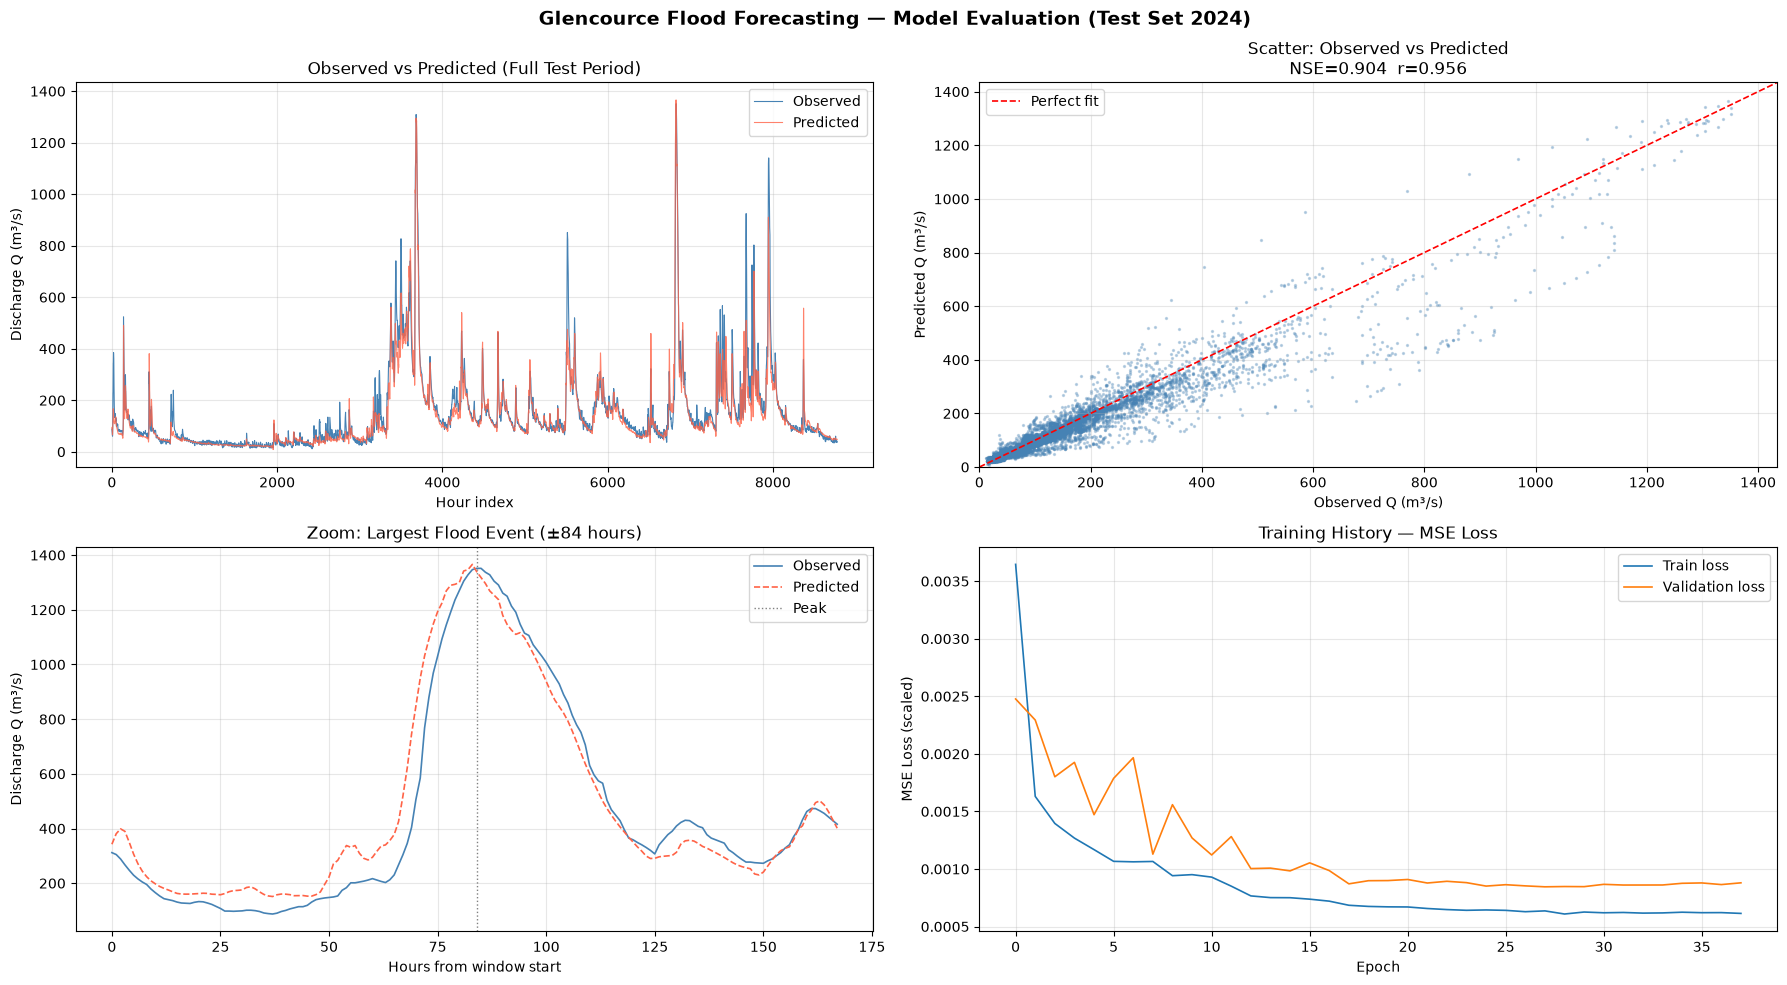

Peak observed Q : 1351.52
Peak predicted Q: 1339.31
Peak error      : 12.22 (0.9%)


In [11]:
# ── All 4 Plots in One Cell ───────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(18, 10))
fig.suptitle("Glencource Flood Forecasting — Model Evaluation (Test Set 2024)",
             fontsize=14, fontweight="bold")

# ── Plot 1: Time Series ───────────────────────────────────────────────────
ax = axes[0, 0]
ax.plot(y_obs,  label="Observed",  linewidth=0.8, color="steelblue")
ax.plot(y_pred, label="Predicted", linewidth=0.8, color="tomato", alpha=0.8)
ax.set_title("Observed vs Predicted (Full Test Period)")
ax.set_xlabel("Hour index")
ax.set_ylabel("Discharge Q (m³/s)")
ax.legend()
ax.grid(alpha=0.3)

# ── Plot 2: Scatter ───────────────────────────────────────────────────────
ax = axes[0, 1]
ax.scatter(y_obs, y_pred, s=2, alpha=0.3, color="steelblue")
lim = max(y_obs.max(), y_pred.max()) * 1.05
ax.plot([0, lim], [0, lim], "r--", linewidth=1.2, label="Perfect fit")
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel("Observed Q (m³/s)")
ax.set_ylabel("Predicted Q (m³/s)")
ax.set_title(f"Scatter: Observed vs Predicted\nNSE={nse:.3f}  r={r:.3f}")
ax.legend()
ax.grid(alpha=0.3)

# ── Plot 3: Flood Peak Zoom ───────────────────────────────────────────────
ax = axes[1, 0]
peak_idx  = np.argmax(y_obs)
half_win  = 84                                      # ±84 hours around peak
start     = max(0, peak_idx - half_win)
end       = min(len(y_obs), peak_idx + half_win)
ax.plot(y_obs[start:end],  label="Observed",  linewidth=1.2, color="steelblue")
ax.plot(y_pred[start:end], label="Predicted", linewidth=1.2, color="tomato",
        linestyle="--")
ax.axvline(x=peak_idx - start, color="gray", linestyle=":", linewidth=1,
           label="Peak")
ax.set_title("Zoom: Largest Flood Event (±84 hours)")
ax.set_xlabel("Hours from window start")
ax.set_ylabel("Discharge Q (m³/s)")
ax.legend()
ax.grid(alpha=0.3)

# ── Plot 4: Training Loss ─────────────────────────────────────────────────
ax = axes[1, 1]
ax.plot(history.history["loss"],     label="Train loss",      linewidth=1.2)
ax.plot(history.history["val_loss"], label="Validation loss", linewidth=1.2)
ax.set_title("Training History — MSE Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE Loss (scaled)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("model_evaluation.png", dpi=150)
plt.show()

# ── Peak summary ──────────────────────────────────────────────────────────
print(f"Peak observed Q : {y_obs[peak_idx]:.2f}")
print(f"Peak predicted Q: {y_pred[peak_idx]:.2f}")
print(f"Peak error      : {abs(y_obs[peak_idx]-y_pred[peak_idx]):.2f} "
      f"({abs(y_obs[peak_idx]-y_pred[peak_idx])/y_obs[peak_idx]*100:.1f}%)")

## 10. Physics-Informed LSTM (PINN): Model Definition


In [12]:
# ── PINN-LSTM: Physics-Informed Loss Function ─────────────────────────────
# Replaces plain MSE with 3-component loss:
#   1. Data loss     — standard MSE
#   2. Peak loss     — extra weight on high flows to fix FHV weakness

def pinn_loss(y_true, y_pred):
    mse = tf.reduce_mean(tf.square(y_true - y_pred))

    # y_true is MinMax-scaled to [0,1].
    # Normalise weights so that the top of the scale (1.0) gets ~4x weight,
    # regardless of the actual discharge magnitude.
    # weight at y_true=0.0 → 1.0x  (low flow, baseline)
    # weight at y_true=1.0 → 4.0x  (peak flow, maximum emphasis)
    weights  = 1.0 + 3.0 * (y_true / tf.reduce_max(y_true + 1e-8))
    peak_mse = tf.reduce_mean(weights * tf.square(y_true - y_pred))

    return mse + 0.5 * peak_mse

set_seed()
# ── Build PINN-LSTM (same architecture, different loss) ───────────────────
pinn_model = keras.Sequential([
    layers.Input(shape=(LOOKBACK, len(FEATURE_COLS))),
    layers.LSTM(64, return_sequences=True),
    layers.Dropout(0.10),
    layers.LSTM(32),
    layers.Dropout(0.20),
    layers.Dense(32, activation="relu"),
    layers.Dense(1)
], name="PINN_LSTM")

# Only change from standard LSTM: loss=pinn_loss instead of loss="mse"
pinn_model.compile(optimizer=keras.optimizers.Adam(0.001), loss=pinn_loss)
pinn_model.summary()

# ── Train ──────────────────────────────────────────────────────────────────
pinn_history = pinn_model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=256,
    shuffle=True,
    validation_data=(X_val, y_val),
    callbacks=[
        keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=4)
    ]
)

Model: "PINN_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 504, 64)        │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 504, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,937 (124.75 KB)

 Trainable params: 31,937 (124.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100


E0000 00:00:1793545416.125625 1970913 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 435ms/step - loss: 0.0082

E0000 00:00:1793545462.468169 1970913 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


101/101 ━━━━━━━━━━━━━━━━━━━━ 53s 506ms/step - loss: 0.0082 - val_loss: 0.0066 - learning_rate: 0.0010
Epoch 2/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 48s 475ms/step - loss: 0.0035 - val_loss: 0.0057 - learning_rate: 0.0010
Epoch 3/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 48s 472ms/step - loss: 0.0031 - val_loss: 0.0053 - learning_rate: 0.0010
Epoch 4/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 47s 468ms/step - loss: 0.0028 - val_loss: 0.0047 - learning_rate: 0.0010
Epoch 5/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 48s 472ms/step - loss: 0.0026 - val_loss: 0.0040 - learning_rate: 0.0010
Epoch 6/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 47s 469ms/step - loss: 0.0024 - val_loss: 0.0044 - learning_rate: 0.0010
Epoch 7/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 47s 463ms/step - loss: 0.0023 - val_loss: 0.0043 - learning_rate: 0.0010
Epoch 8/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 47s 462ms/step - loss: 0.0022 - val_loss: 0.0033 - learning_rate: 0.0010
Epoch 9/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 47s 464ms/step - loss: 0.0021 - val_loss: 0.0041 - learning

## 13. Evaluate the PINN on the Test Set


In [13]:
# ── Evaluate PINN on Test Set ─────────────────────────────────────────────
pinn_preds = pinn_model.predict(X_test, verbose=0)

# Inverse transform — use same scaler but new variable names
pinn_y_pred = np.clip(scaler_y.inverse_transform(pinn_preds).ravel(), 0, None)
pinn_y_obs  = scaler_y.inverse_transform(y_test.reshape(-1, 1)).ravel()
# Note: pinn_y_obs == y_obs (same test set) but named separately to avoid confusion

# ── PINN Metrics ──────────────────────────────────────────────────────────
pinn_nse   = 1 - np.sum((pinn_y_obs - pinn_y_pred)**2) / np.sum((pinn_y_obs - pinn_y_obs.mean())**2)
pinn_r     = np.corrcoef(pinn_y_obs, pinn_y_pred)[0, 1]
pinn_alpha = pinn_y_pred.std() / pinn_y_obs.std()
pinn_beta  = (pinn_y_pred.mean() - pinn_y_obs.mean()) / pinn_y_obs.std()

# ── FHV (corrected) ────────────────────────────────────────────────────────
pinn_k             = int(np.ceil(0.02 * len(pinn_y_obs)))
pinn_top_indices   = np.argsort(pinn_y_obs)[-pinn_k:]     # top 2% timestamps from OBSERVED
pinn_obs_at_peaks  = pinn_y_obs[pinn_top_indices]          # observed Q at those timestamps
pinn_pred_at_peaks = pinn_y_pred[pinn_top_indices]         # predicted Q at same timestamps
pinn_fhv           = (pinn_pred_at_peaks.sum() - pinn_obs_at_peaks.sum()) / pinn_obs_at_peaks.sum() * 100


# ── Side-by-side comparison ───────────────────────────────────────────────
print("=" * 55)
print("         Model Comparison (Test Set)")
print("=" * 55)
print(f"{'Metric':<10} {'Standard LSTM':>15} {'PINN-LSTM':>12} {'Change':>10}")
print("-" * 55)
print(f"{'NSE':<10} {nse:>15.3f} {pinn_nse:>12.3f} {pinn_nse-nse:>+10.3f}")
print(f"{'r':<10} {r:>15.3f} {pinn_r:>12.3f} {pinn_r-r:>+10.3f}")
print(f"{'Alpha':<10} {alpha:>15.3f} {pinn_alpha:>12.3f} {pinn_alpha-alpha:>+10.3f}")
print(f"{'Beta':<10} {beta:>15.3f} {pinn_beta:>12.3f} {pinn_beta-beta:>+10.3f}")
print(f"{'FHV (%)':<10} {fhv:>15.1f} {pinn_fhv:>12.1f} {pinn_fhv-fhv:>+10.1f}")

E0000 00:00:1793547378.685641 1970913 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


         Model Comparison (Test Set)
Metric       Standard LSTM    PINN-LSTM     Change
-------------------------------------------------------
NSE                  0.904        0.902     -0.003
r                    0.956        0.956     -0.000
Alpha                0.894        0.880     -0.014
Beta                -0.076       -0.075     +0.001
FHV (%)              -16.9        -18.9       -2.0


## 15. Plots: Observed vs LSTM vs PINN


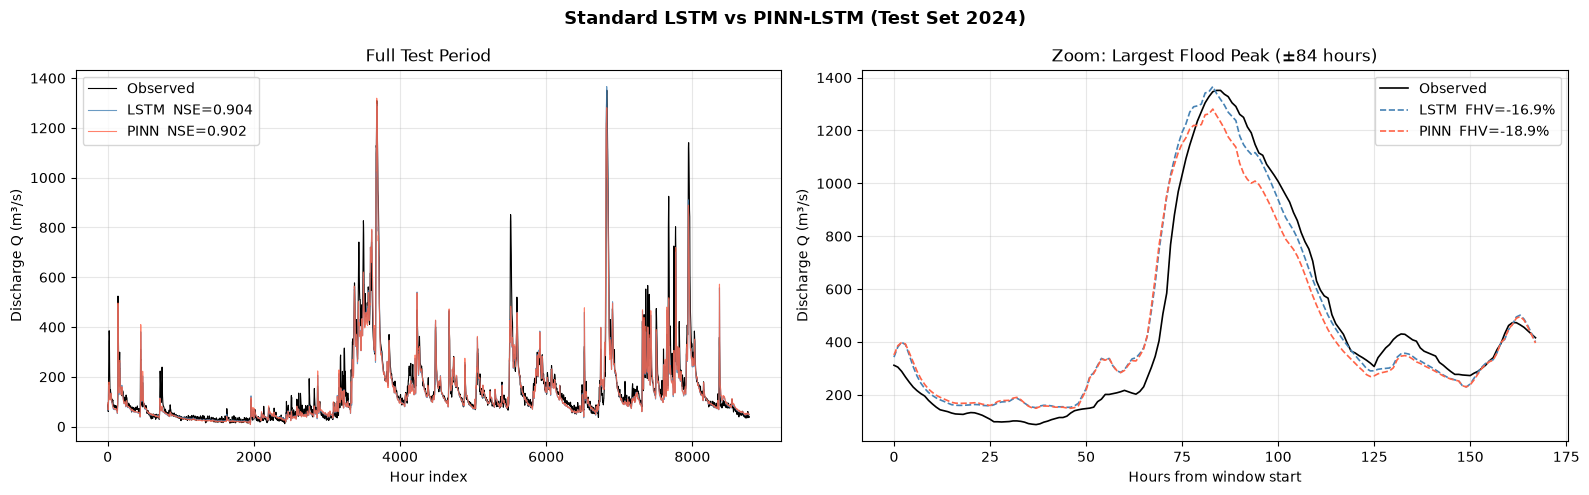

In [14]:
# ── Plot: Standard LSTM vs PINN-LSTM ──────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle("Standard LSTM vs PINN-LSTM (Test Set 2024)", fontsize=13, fontweight="bold")

# Time series
ax = axes[0]
ax.plot(pinn_y_obs,  label="Observed",       color="black",      linewidth=0.8)
ax.plot(y_pred,      label=f"LSTM  NSE={nse:.3f}",      color="steelblue",  linewidth=0.8, alpha=0.8)
ax.plot(pinn_y_pred, label=f"PINN  NSE={pinn_nse:.3f}", color="tomato",     linewidth=0.8, alpha=0.8)
ax.set_title("Full Test Period")
ax.set_xlabel("Hour index")
ax.set_ylabel("Discharge Q (m³/s)")
ax.legend(); ax.grid(alpha=0.3)

# Flood peak zoom
ax = axes[1]
peak_idx = np.argmax(pinn_y_obs)
lo = max(0, peak_idx - 84)
hi = min(len(pinn_y_obs), peak_idx + 84)
ax.plot(pinn_y_obs[lo:hi],  label="Observed",       color="black",     linewidth=1.2)
ax.plot(y_pred[lo:hi],      label=f"LSTM  FHV={fhv:.1f}%",      color="steelblue", linewidth=1.2, linestyle="--")
ax.plot(pinn_y_pred[lo:hi], label=f"PINN  FHV={pinn_fhv:.1f}%", color="tomato",    linewidth=1.2, linestyle="--")
ax.set_title("Zoom: Largest Flood Peak (±84 hours)")
ax.set_xlabel("Hours from window start")
ax.set_ylabel("Discharge Q (m³/s)")
ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("lstm_vs_pinn.png", dpi=150)
plt.show()

## Cross Validation

In [15]:
# ── Walk-Forward Time Series Cross Validation ─────────────────────────────
# Standard k-fold is NOT used — it breaks temporal order and causes leakage.
# Walk-forward validation always trains on past, validates on future.
# Test set (2024) is held out completely — never touched during CV.
#
# Fold 1: Train 2020      → Val 2021
# Fold 2: Train 2020-2021 → Val 2022
# Fold 3: Train 2020-2022 → Val 2023
# Final Test: 2024 — held out completely, never used in CV

from sklearn.preprocessing import MinMaxScaler

CV_FOLDS = [
    {"train_end": "2020-12-31 23:00", "val_end": "2021-12-31 23:00"},
    {"train_end": "2021-12-31 23:00", "val_end": "2022-12-31 23:00"},
    {"train_end": "2022-12-31 23:00", "val_end": "2023-12-31 23:00"},
]

cv_results  = []   # metrics per fold
cv_plot_data = []  # observed + predictions per fold (for time series plots)

for fold_num, fold in enumerate(CV_FOLDS):
    print(f"\n{'='*60}")
    print(f"FOLD {fold_num+1}: Train → {fold['train_end'][:4]} | Val → {fold['val_end'][:4]}")
    print(f"{'='*60}")

    # ── Split ──────────────────────────────────────────────────────────────
    fold_train = df.loc[:fold["train_end"]]
    fold_val   = df.loc[fold["train_end"]:fold["val_end"]].iloc[1:]
    fold_df    = df.loc[:fold["val_end"]]

    # ── Scale — fit on training fold ONLY (no leakage) ────────────────────
    fold_scaler_x = MinMaxScaler().fit(fold_train[FEATURE_COLS])
    fold_scaler_y = MinMaxScaler().fit(fold_train[TARGET_COL])

    fold_x_all = fold_scaler_x.transform(
                     fold_df[FEATURE_COLS].ffill(limit=3).fillna(0))
    fold_y_all = fold_scaler_y.transform(
                     fold_df[TARGET_COL].ffill(limit=3).fillna(0)).ravel()

    # ── Timestamp gap detection ────────────────────────────────────────────
    fold_time_diff = fold_df.index.to_series().diff()
    fold_is_gap    = fold_time_diff > pd.Timedelta("1h")
    fold_gap_locs  = set(np.where(fold_is_gap)[0])

    fold_i1 = fold_df.index.get_loc(fold_train.index[-1])
    fold_n  = len(fold_df)

    # ── Window builder ─────────────────────────────────────────────────────
    def fold_windows(idx):
        valid = []
        for i in idx:
            window_rows = set(range(i - LOOKBACK + 1, i + 1))
            if window_rows.intersection(fold_gap_locs):
                continue
            x_win = fold_x_all[i - LOOKBACK + 1 : i + 1]
            if not np.isfinite(x_win).all():
                continue
            if not np.isfinite(fold_y_all[i]):
                continue
            valid.append(i)
        valid = np.array(valid)
        if len(valid) == 0:
            return np.empty((0, LOOKBACK, len(FEATURE_COLS))), np.empty(0), np.array([], dtype=int)
        X = np.stack([fold_x_all[i - LOOKBACK + 1 : i + 1] for i in valid])
        y = fold_y_all[valid]
        return X, y, valid  # also return valid indices for timestamps

    tr_idx = np.arange(LOOKBACK - 1, fold_i1)
    va_idx = np.arange(fold_i1, fold_n - FORECAST_HORIZON)

    X_cv_train, y_cv_train, _        = fold_windows(tr_idx)
    X_cv_val,   y_cv_val,   va_valid = fold_windows(va_idx)

    print(f"Train windows: {X_cv_train.shape[0]} | Val windows: {X_cv_val.shape[0]}")

    if X_cv_train.shape[0] == 0 or X_cv_val.shape[0] == 0:
        print("  Skipping fold — not enough data")
        continue

    # ── Val set timestamps (for plotting) ─────────────────────────────────
    val_timestamps = fold_df.index[va_valid]

    # ── Train Standard LSTM ────────────────────────────────────────────────
    set_seed(SEED + fold_num)
    lstm_fold = keras.Sequential([
        layers.Input(shape=(LOOKBACK, len(FEATURE_COLS))),
        layers.LSTM(64, return_sequences=True),
        layers.Dropout(0.10),
        layers.LSTM(32),
        layers.Dropout(0.20),
        layers.Dense(32, activation="relu"),
        layers.Dense(1)
    ], name=f"LSTM_fold{fold_num+1}")
    lstm_fold.compile(optimizer=keras.optimizers.Adam(0.001), loss="mse")
    lstm_fold.fit(
        X_cv_train, y_cv_train,
        epochs=100, batch_size=256, shuffle=True,
        validation_data=(X_cv_val, y_cv_val),
        callbacks=[
            keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=4)
        ],
        verbose=0
    )

    # ── Train PINN-LSTM ────────────────────────────────────────────────────
    set_seed(SEED + fold_num)
    pinn_fold = keras.Sequential([
        layers.Input(shape=(LOOKBACK, len(FEATURE_COLS))),
        layers.LSTM(64, return_sequences=True),
        layers.Dropout(0.10),
        layers.LSTM(32),
        layers.Dropout(0.20),
        layers.Dense(32, activation="relu"),
        layers.Dense(1)
    ], name=f"PINN_fold{fold_num+1}")
    pinn_fold.compile(optimizer=keras.optimizers.Adam(0.001), loss=pinn_loss)
    pinn_fold.fit(
        X_cv_train, y_cv_train,
        epochs=100, batch_size=256, shuffle=True,
        validation_data=(X_cv_val, y_cv_val),
        callbacks=[
            keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=4)
        ],
        verbose=0
    )

    # ── Inverse transform predictions ─────────────────────────────────────
    cv_y_obs = fold_scaler_y.inverse_transform(
                   y_cv_val.reshape(-1, 1)).ravel()

    lstm_raw  = lstm_fold.predict(X_cv_val, verbose=0)
    lstm_pred = np.clip(fold_scaler_y.inverse_transform(lstm_raw).ravel(), 0, None)

    pinn_raw  = pinn_fold.predict(X_cv_val, verbose=0)
    pinn_pred = np.clip(fold_scaler_y.inverse_transform(pinn_raw).ravel(), 0, None)

    # ── Helper: compute all metrics for one set of predictions ────────────
    def compute_metrics(obs, pred):
        nse   = 1 - np.sum((obs - pred)**2) / np.sum((obs - obs.mean())**2)
        r     = np.corrcoef(obs, pred)[0, 1]
        alpha = pred.std() / obs.std()
        beta  = (pred.mean() - obs.mean()) / obs.std()
        k     = int(np.ceil(0.02 * len(obs)))
        top   = np.argsort(obs)[-k:]
        fhv   = (pred[top].sum() - obs[top].sum()) / obs[top].sum() * 100
        q20, q70 = np.percentile(obs, 20), np.percentile(obs, 70)
        mid   = (obs >= q20) & (obs <= q70)
        fms   = (pred[mid].sum() - obs[mid].sum()) / obs[mid].sum() * 100
        q30   = np.percentile(obs, 30)
        low   = obs <= q30
        flv   = (pred[low].sum() - obs[low].sum()) / obs[low].sum() * 100
        return dict(nse=nse, r=r, alpha=alpha, beta=beta,
                    fhv=fhv, fms=fms, flv=flv)

    lm = compute_metrics(cv_y_obs, lstm_pred)
    pm = compute_metrics(cv_y_obs, pinn_pred)

    print(f"LSTM → NSE:{lm['nse']:.3f}  r:{lm['r']:.3f}  FHV:{lm['fhv']:.1f}%  FMS:{lm['fms']:.1f}%  FLV:{lm['flv']:.1f}%")
    print(f"PINN → NSE:{pm['nse']:.3f}  r:{pm['r']:.3f}  FHV:{pm['fhv']:.1f}%  FMS:{pm['fms']:.1f}%  FLV:{pm['flv']:.1f}%")

    # ── Store metrics ──────────────────────────────────────────────────────
    cv_results.append({
        "Fold":         fold_num + 1,
        "Val Year":     fold["val_end"][:4],
        "LSTM_NSE":     lm["nse"],  "LSTM_r":   lm["r"],
        "LSTM_Alpha":   lm["alpha"],"LSTM_Beta": lm["beta"],
        "LSTM_FHV":     lm["fhv"],  "LSTM_FMS": lm["fms"],  "LSTM_FLV": lm["flv"],
        "PINN_NSE":     pm["nse"],  "PINN_r":   pm["r"],
        "PINN_Alpha":   pm["alpha"],"PINN_Beta": pm["beta"],
        "PINN_FHV":     pm["fhv"],  "PINN_FMS": pm["fms"],  "PINN_FLV": pm["flv"],
    })

    # ── Store arrays for time series plots ────────────────────────────────
    cv_plot_data.append({
        "fold_num":   fold_num + 1,
        "val_year":   fold["val_end"][:4],
        "timestamps": val_timestamps,
        "obs":        cv_y_obs,
        "lstm_pred":  lstm_pred,
        "pinn_pred":  pinn_pred,
        "lm":         lm,
        "pm":         pm,
    })

# ── Summary Table ──────────────────────────────────────────────────────────
cv_df = pd.DataFrame(cv_results)
print("\n" + "="*75)
print("              Walk-Forward Cross Validation Summary")
print("="*75)
print(f"{'Metric':<12} {'LSTM F1':>9} {'LSTM F2':>9} {'LSTM F3':>9} {'LSTM Mean':>11} | "
      f"{'PINN F1':>9} {'PINN F2':>9} {'PINN F3':>9} {'PINN Mean':>11}")
print("-"*75)
for metric, lstm_col, pinn_col in [
    ("NSE",     "LSTM_NSE", "PINN_NSE"),
    ("r",       "LSTM_r",   "PINN_r"),
    ("Alpha",   "LSTM_Alpha","PINN_Alpha"),
    ("FHV (%)", "LSTM_FHV", "PINN_FHV"),
    ("FMS (%)", "LSTM_FMS", "PINN_FMS"),
    ("FLV (%)", "LSTM_FLV", "PINN_FLV"),
]:
    lv = cv_df[lstm_col].tolist()
    pv = cv_df[pinn_col].tolist()
    print(f"{metric:<12} {lv[0]:>9.3f} {lv[1]:>9.3f} {lv[2]:>9.3f} {cv_df[lstm_col].mean():>11.3f} | "
          f"{pv[0]:>9.3f} {pv[1]:>9.3f} {pv[2]:>9.3f} {cv_df[pinn_col].mean():>11.3f}")


FOLD 1: Train → 2020 | Val → 2021
Train windows: 8280 | Val windows: 8755


E0000 00:00:1793547394.303204 1970913 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1793547411.144699 1970913 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

LSTM → NSE:0.851  r:0.933  FHV:-24.6%  FMS:6.1%  FLV:9.1%
PINN → NSE:0.854  r:0.932  FHV:-23.1%  FMS:8.3%  FLV:16.7%

FOLD 2: Train → 2021 | Val → 2022
Train windows: 17040 | Val windows: 8755


E0000 00:00:1793547962.870002 1970913 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1793547993.143694 1970913 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

LSTM → NSE:0.935  r:0.969  FHV:-11.4%  FMS:14.9%  FLV:41.2%
PINN → NSE:0.931  r:0.968  FHV:-11.8%  FMS:18.6%  FLV:52.1%

FOLD 3: Train → 2022 | Val → 2023
Train windows: 25800 | Val windows: 8755


E0000 00:00:1793550983.124466 1970913 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1793551026.283765 1970913 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

LSTM → NSE:0.898  r:0.950  FHV:-15.0%  FMS:-2.7%  FLV:-1.0%
PINN → NSE:0.898  r:0.948  FHV:-15.8%  FMS:6.0%  FLV:20.8%

              Walk-Forward Cross Validation Summary
Metric         LSTM F1   LSTM F2   LSTM F3   LSTM Mean |   PINN F1   PINN F2   PINN F3   PINN Mean
---------------------------------------------------------------------------
NSE              0.851     0.935     0.898       0.894 |     0.854     0.931     0.898       0.894
r                0.933     0.969     0.950       0.950 |     0.932     0.968     0.948       0.949
Alpha            0.812     0.912     0.926       0.884 |     0.823     0.911     0.907       0.880
FHV (%)        -24.566   -11.421   -15.012     -17.000 |   -23.072   -11.844   -15.765     -16.894
FMS (%)          6.081    14.877    -2.706       6.084 |     8.269    18.646     6.024      10.980
FLV (%)          9.092    41.216    -1.022      16.428 |    16.663    52.130    20.797      29.863


## Cross Validation Plot

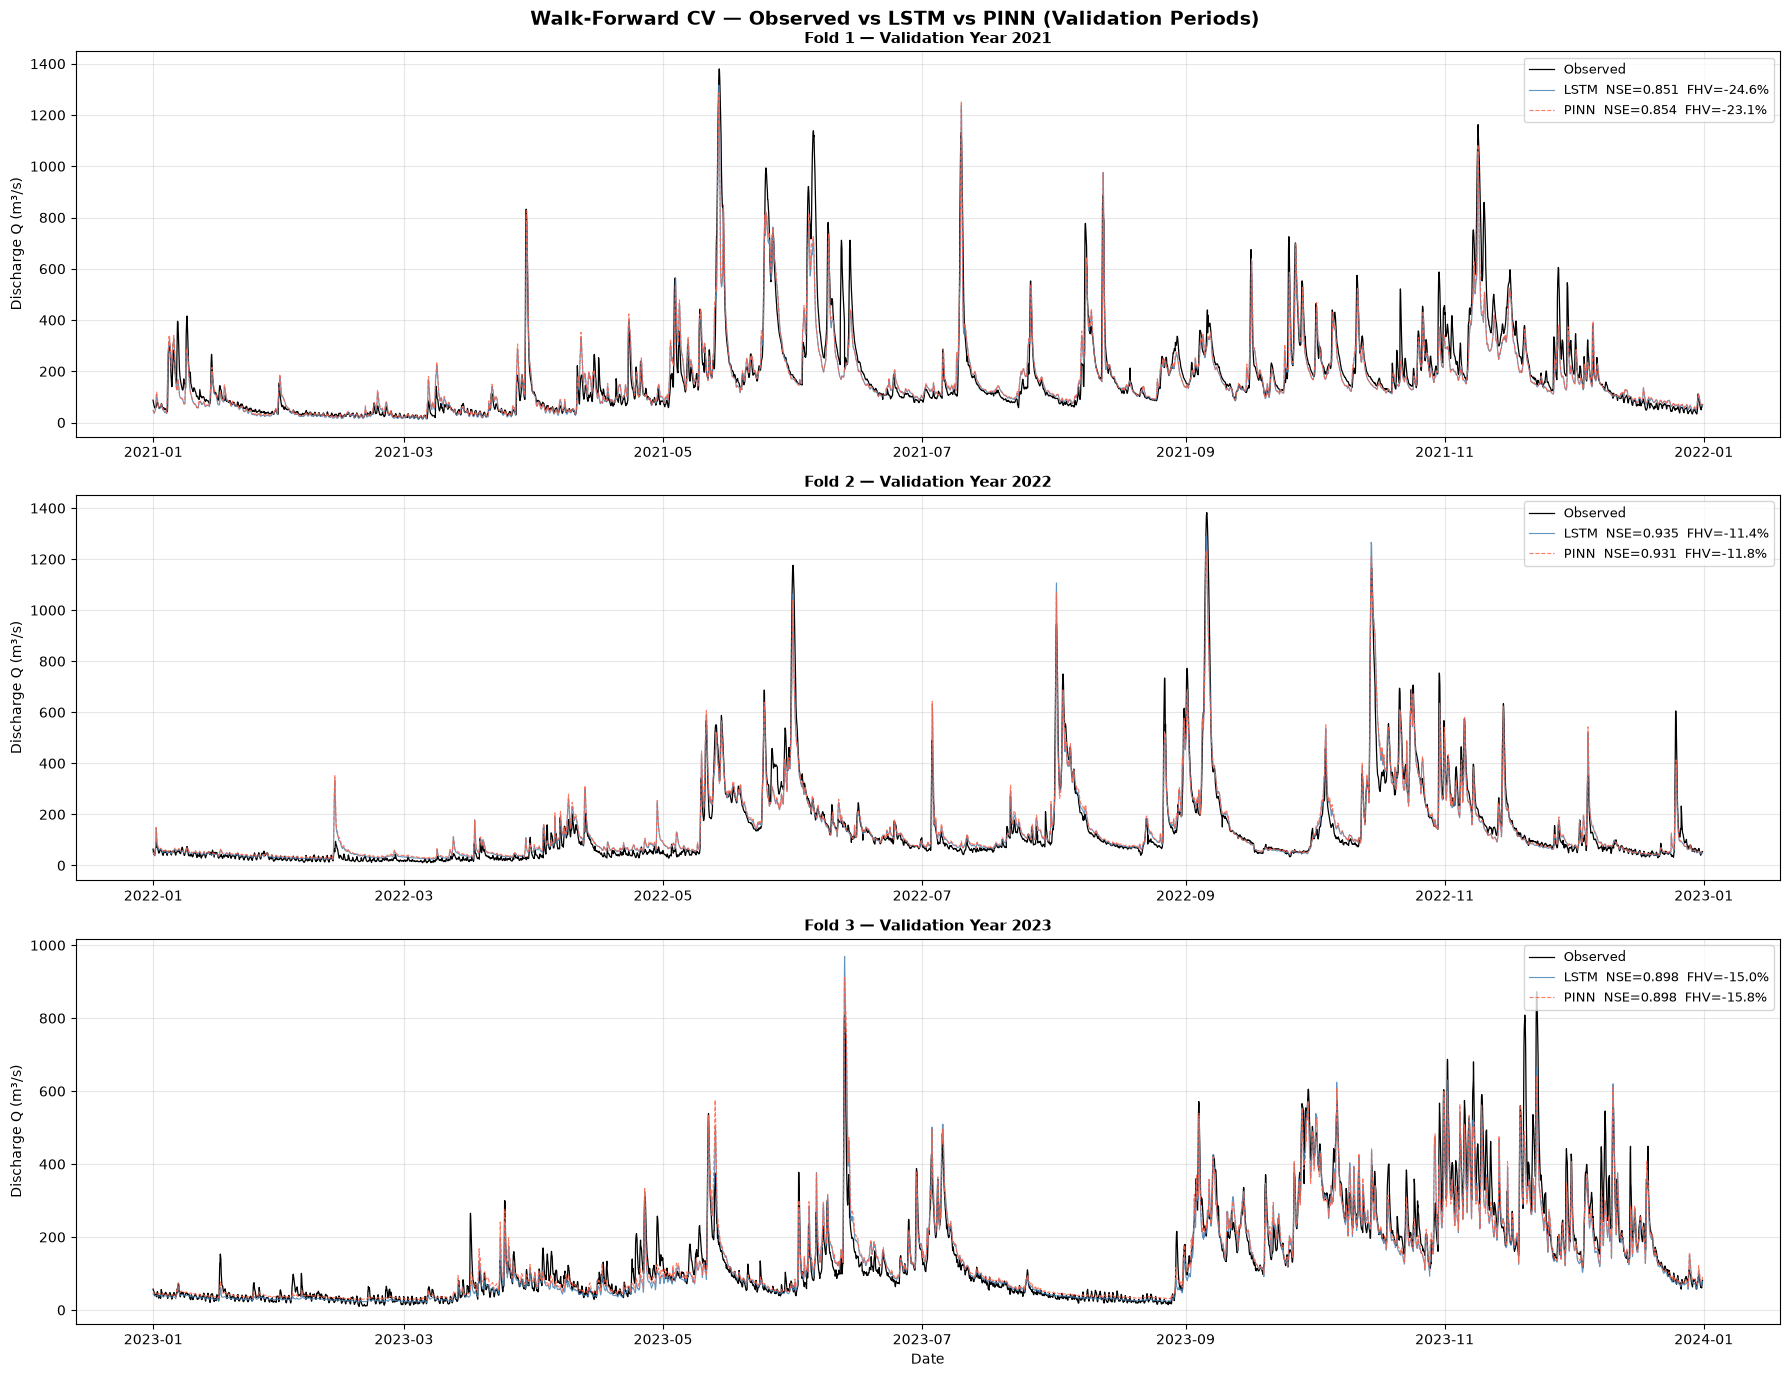

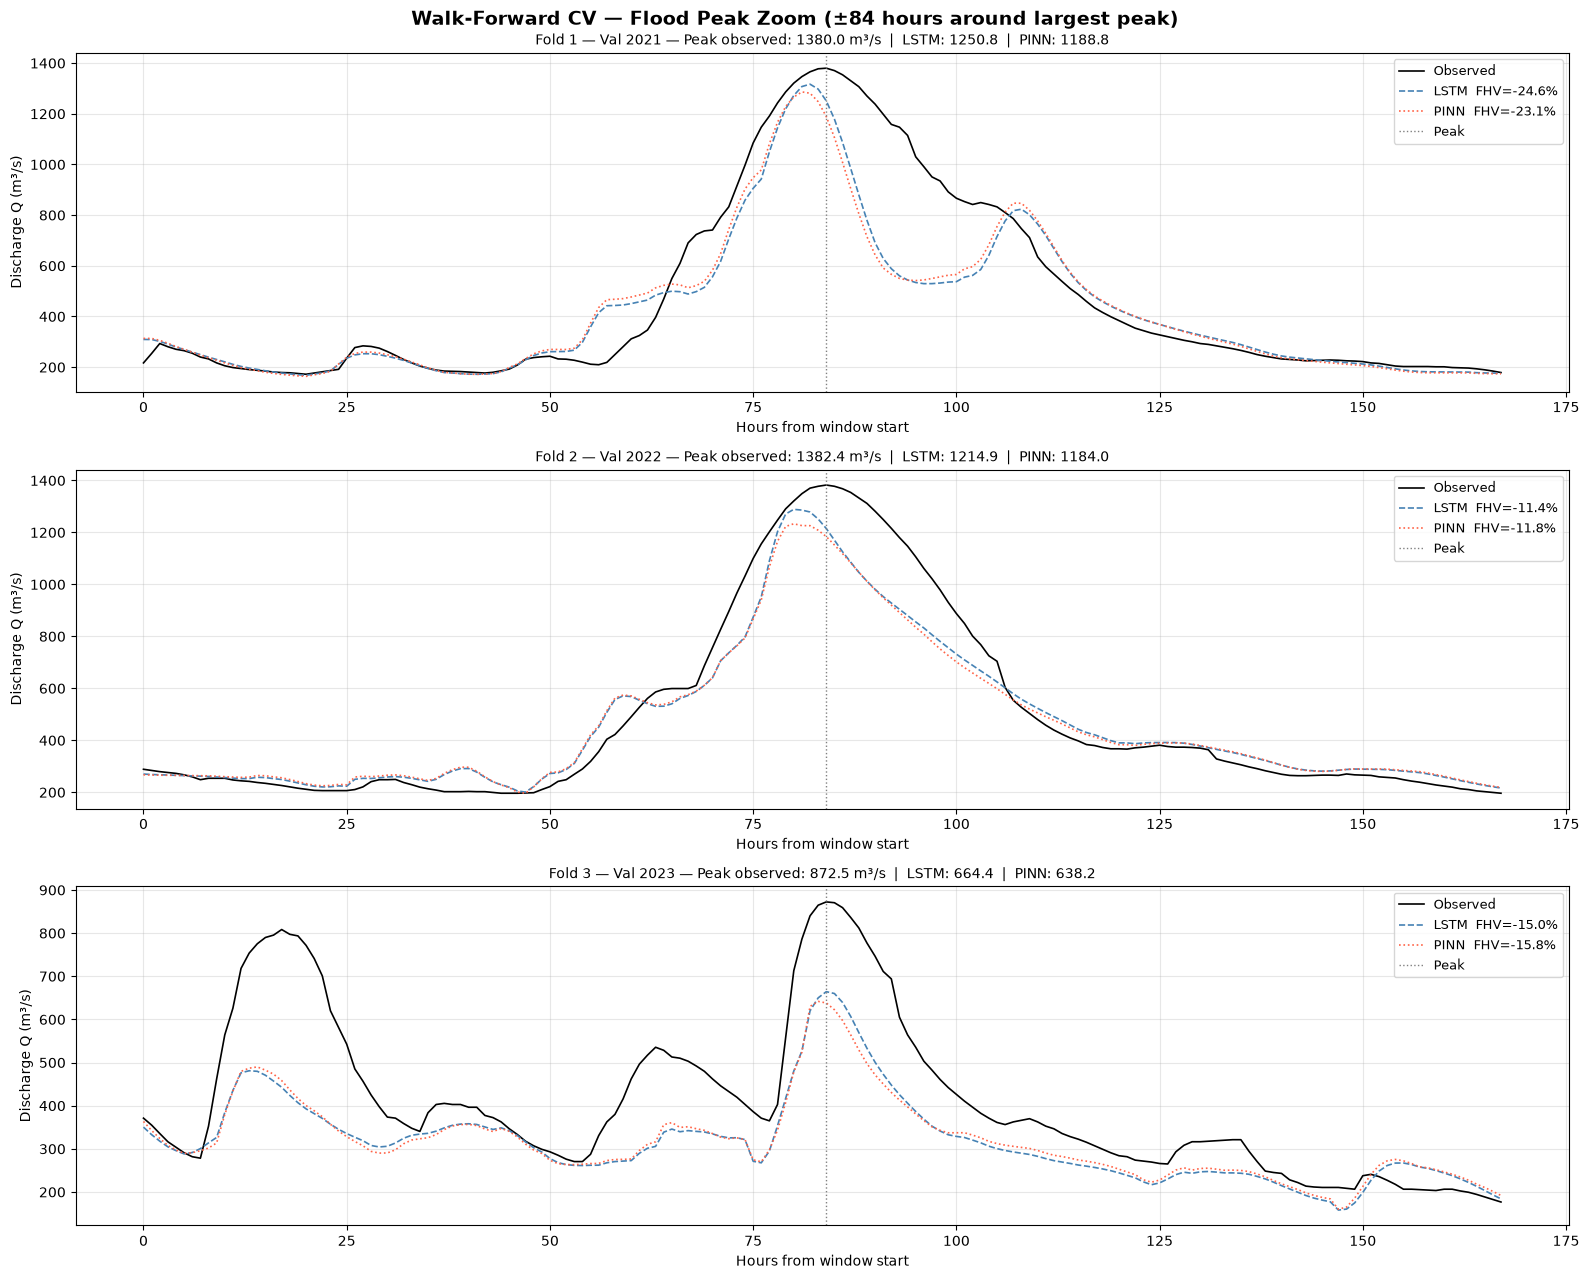

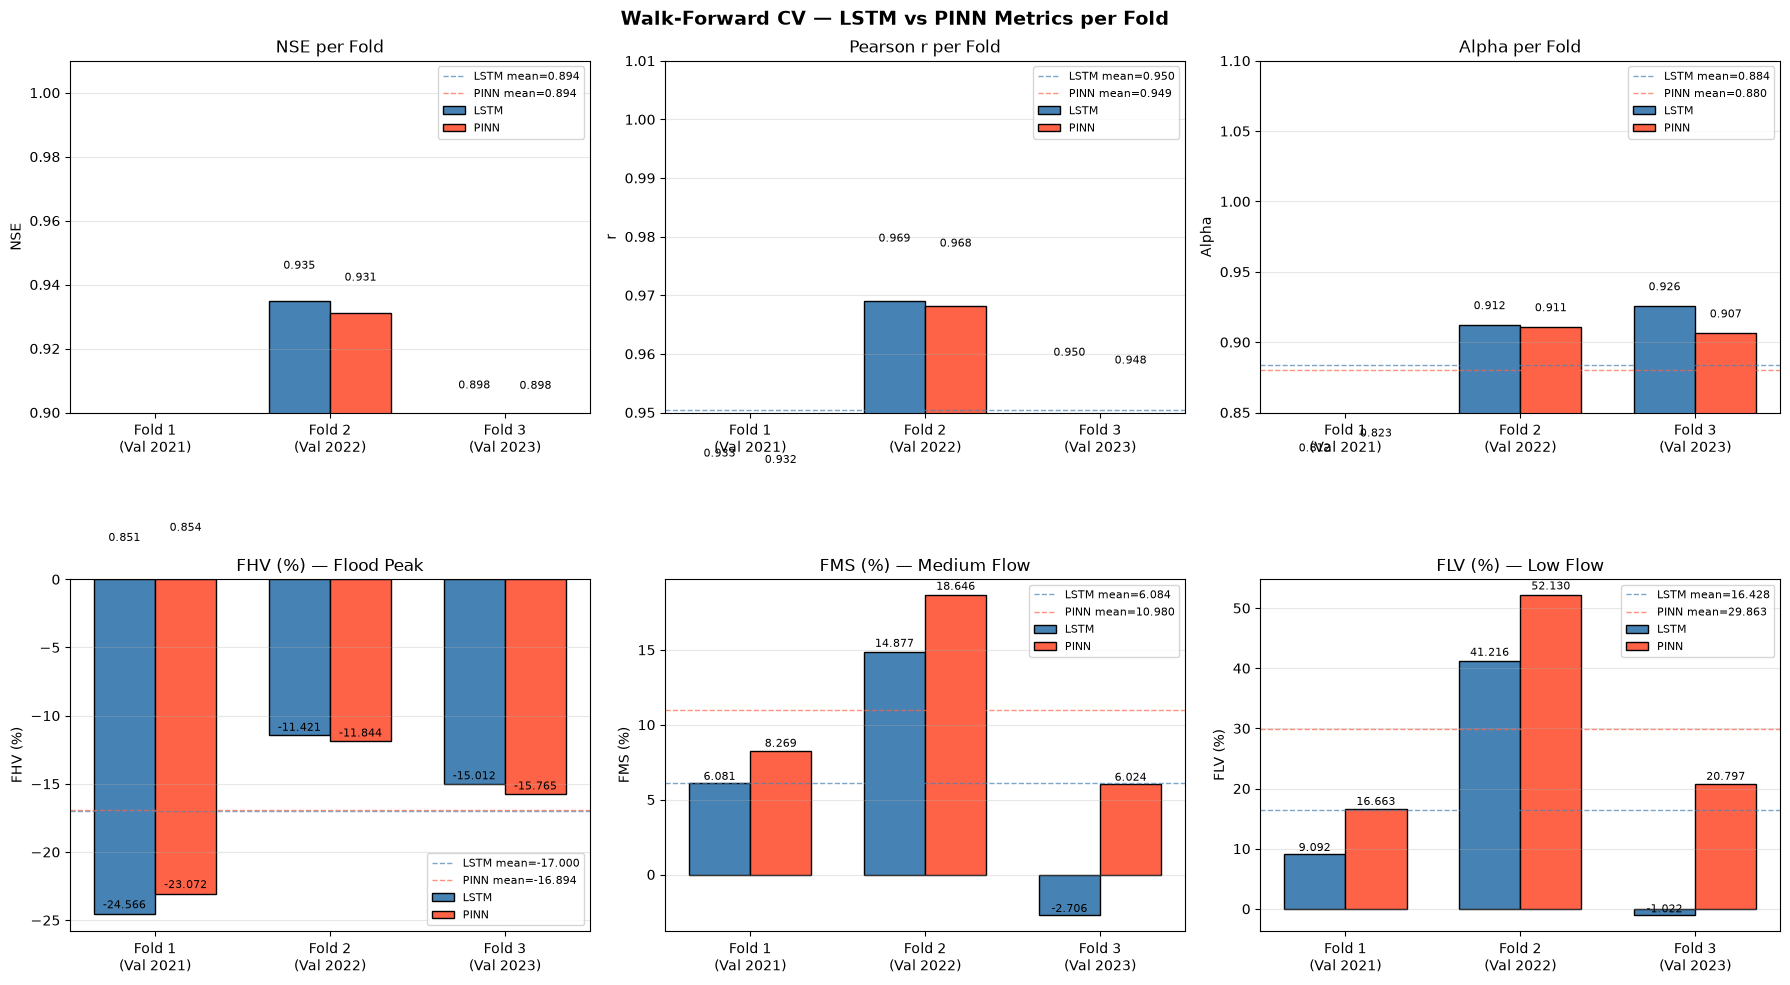

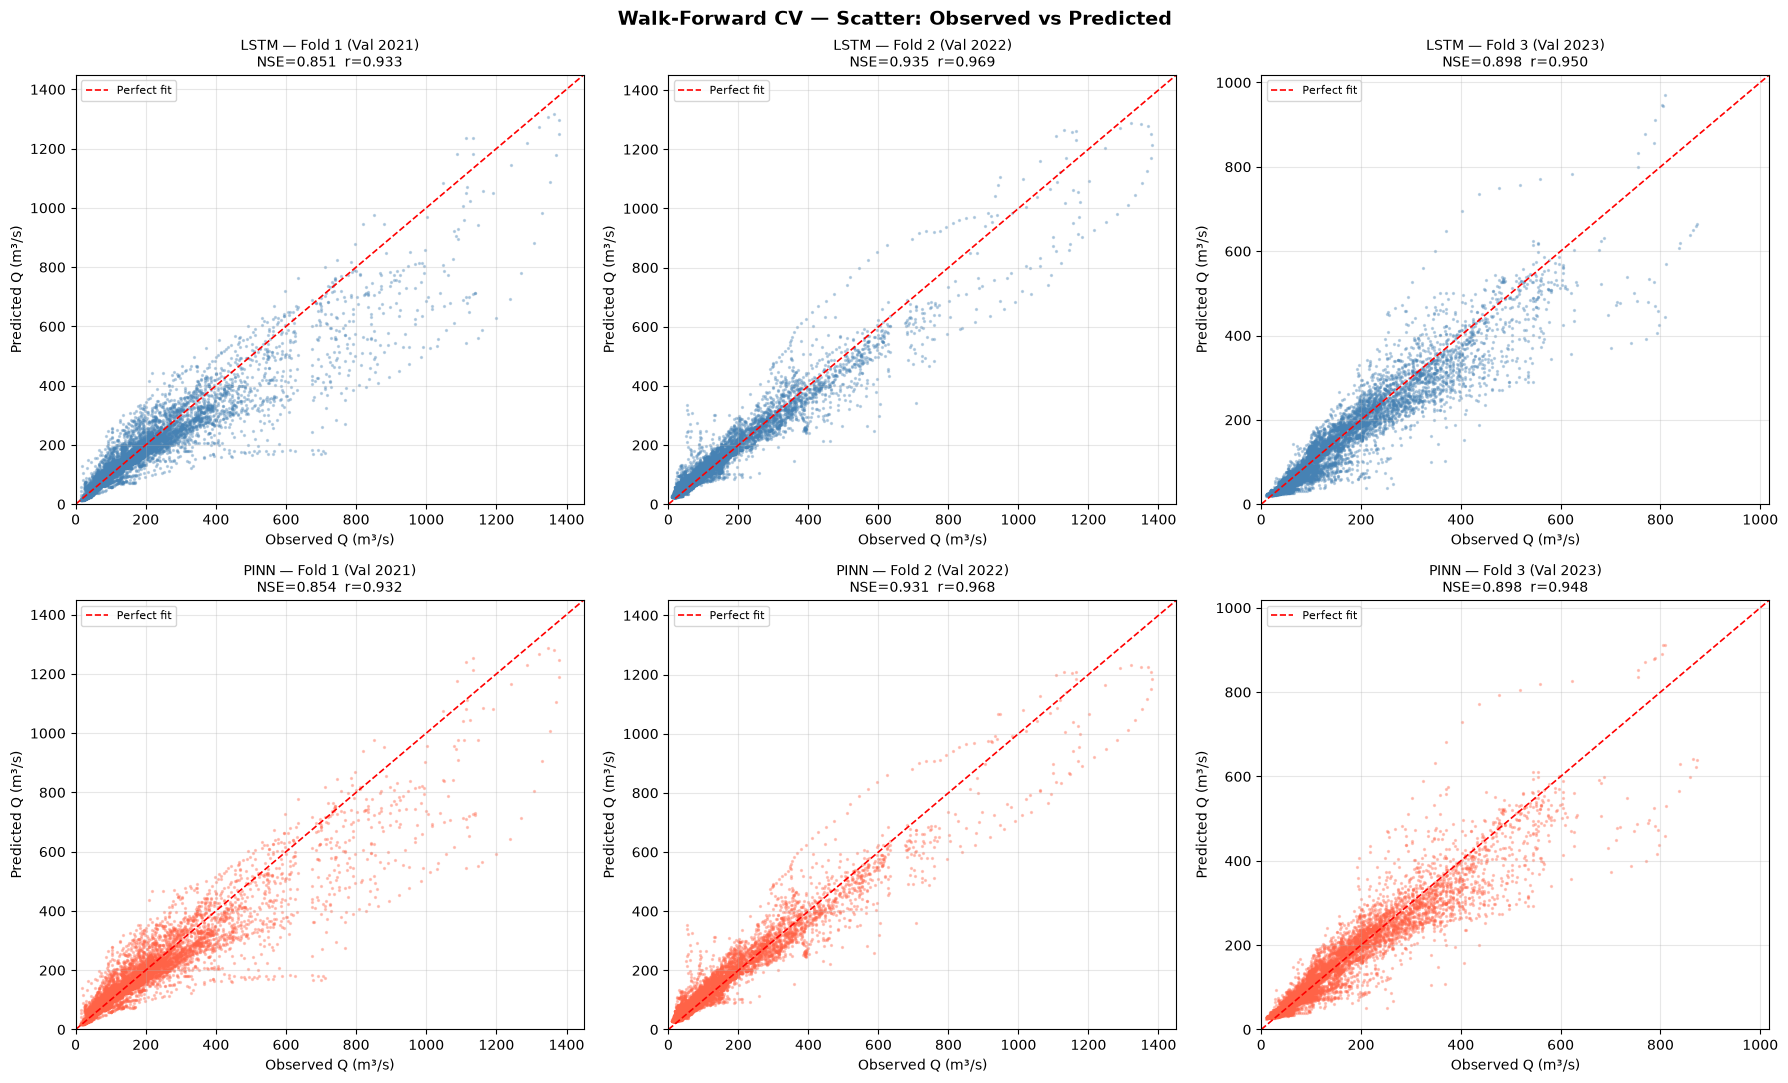


           Walk-Forward CV — Final Summary (LSTM vs PINN)
Metric         LSTM F1   LSTM F2   LSTM F3    LSTM μ |   PINN F1   PINN F2   PINN F3    PINN μ
--------------------------------------------------------------------------------
NSE              0.851     0.935     0.898     0.894 |     0.854     0.931     0.898     0.894
r                0.933     0.969     0.950     0.950 |     0.932     0.968     0.948     0.949
Alpha            0.812     0.912     0.926     0.884 |     0.823     0.911     0.907     0.880
FHV (%)        -24.566   -11.421   -15.012   -17.000 |   -23.072   -11.844   -15.765   -16.894
FMS (%)          6.081    14.877    -2.706     6.084 |     8.269    18.646     6.024    10.980
FLV (%)          9.092    41.216    -1.022    16.428 |    16.663    52.130    20.797    29.863


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# PART A — Time Series Plots: Observed vs LSTM vs PINN per fold
# ═══════════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(3, 1, figsize=(18, 14), sharex=False)
fig.suptitle("Walk-Forward CV — Observed vs LSTM vs PINN (Validation Periods)",
             fontsize=14, fontweight="bold")

for ax, pd_ in zip(axes, cv_plot_data):
    ts   = pd_["timestamps"]
    obs  = pd_["obs"]
    lp   = pd_["lstm_pred"]
    pp   = pd_["pinn_pred"]
    lm   = pd_["lm"]

    pm   = pd_["pm"]

    ax.plot(ts, obs, label="Observed",
            color="black", linewidth=0.9)
    ax.plot(ts, lp,  label=f"LSTM  NSE={lm['nse']:.3f}  FHV={lm['fhv']:.1f}%",
            color="steelblue", linewidth=0.8, alpha=0.85)
    ax.plot(ts, pp,  label=f"PINN  NSE={pm['nse']:.3f}  FHV={pm['fhv']:.1f}%",
            color="tomato", linewidth=0.8, alpha=0.85, linestyle="--")

    ax.set_title(f"Fold {pd_['fold_num']} — Validation Year {pd_['val_year']}",
                 fontsize=11, fontweight="bold")
    ax.set_ylabel("Discharge Q (m³/s)")
    ax.legend(loc="upper right", fontsize=9)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.savefig("cv_timeseries.png", dpi=150, bbox_inches="tight")
plt.show()

# ═══════════════════════════════════════════════════════════════════════════
# PART B — Flood Peak Zoom per fold
# ═══════════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(3, 1, figsize=(16, 13), sharex=False)
fig.suptitle("Walk-Forward CV — Flood Peak Zoom (±84 hours around largest peak)",
             fontsize=14, fontweight="bold")

for ax, pd_ in zip(axes, cv_plot_data):
    obs  = pd_["obs"]
    lp   = pd_["lstm_pred"]
    pp   = pd_["pinn_pred"]
    lm   = pd_["lm"]
    pm   = pd_["pm"]

    peak = np.argmax(obs)
    lo   = max(0, peak - 84)
    hi   = min(len(obs), peak + 84)

    ax.plot(obs[lo:hi], label="Observed",
            color="black", linewidth=1.2)
    ax.plot(lp[lo:hi],  label=f"LSTM  FHV={lm['fhv']:.1f}%",
            color="steelblue", linewidth=1.2, linestyle="--")
    ax.plot(pp[lo:hi],  label=f"PINN  FHV={pm['fhv']:.1f}%",
            color="tomato", linewidth=1.2, linestyle=":")
    ax.axvline(x=peak - lo, color="gray", linestyle=":", linewidth=1, label="Peak")

    ax.set_title(f"Fold {pd_['fold_num']} — Val {pd_['val_year']} — "
                 f"Peak observed: {obs[peak]:.1f} m³/s  |  "
                 f"LSTM: {lp[peak]:.1f}  |  PINN: {pp[peak]:.1f}",
                 fontsize=10)
    ax.set_ylabel("Discharge Q (m³/s)")
    ax.set_xlabel("Hours from window start")
    ax.legend(loc="upper right", fontsize=9)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("cv_peak_zoom.png", dpi=150, bbox_inches="tight")
plt.show()

# ═══════════════════════════════════════════════════════════════════════════
# PART C — Metrics Bar Charts: LSTM vs PINN side by side per fold
# ═══════════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Walk-Forward CV — LSTM vs PINN Metrics per Fold",
             fontsize=14, fontweight="bold")

folds     = cv_df["Fold"].tolist()
val_years = cv_df["Val Year"].tolist()
x         = np.arange(len(folds))
w         = 0.35
xlabels   = [f"Fold {f}\n(Val {y})" for f, y in zip(folds, val_years)]

def metric_bars(ax, lstm_col, pinn_col, title, ylabel, ylim=None):
    lv = cv_df[lstm_col].tolist()
    pv = cv_df[pinn_col].tolist()
    b1 = ax.bar(x - w/2, lv, width=w, label="LSTM",
                color="steelblue", edgecolor="black")
    b2 = ax.bar(x + w/2, pv, width=w, label="PINN",
                color="tomato",    edgecolor="black")
    ax.axhline(np.mean(lv), color="steelblue", linestyle="--",
               linewidth=1.0, alpha=0.7, label=f"LSTM mean={np.mean(lv):.3f}")
    ax.axhline(np.mean(pv), color="tomato",    linestyle="--",
               linewidth=1.0, alpha=0.7, label=f"PINN mean={np.mean(pv):.3f}")
    ax.set_xticks(x); ax.set_xticklabels(xlabels)
    ax.set_title(title); ax.set_ylabel(ylabel)
    ax.legend(fontsize=8); ax.grid(alpha=0.3, axis="y")
    if ylim: ax.set_ylim(ylim)
    for bar, val in zip(list(b1)+list(b2), lv+pv):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + abs(bar.get_height())*0.01,
                f"{val:.3f}", ha="center", va="bottom", fontsize=8)

metric_bars(axes[0,0], "LSTM_NSE",   "PINN_NSE",   "NSE per Fold",          "NSE",      ylim=(0.90, 1.01))
metric_bars(axes[0,1], "LSTM_r",     "PINN_r",     "Pearson r per Fold",    "r",        ylim=(0.95, 1.01))
metric_bars(axes[0,2], "LSTM_Alpha", "PINN_Alpha", "Alpha per Fold",        "Alpha",    ylim=(0.85, 1.10))
metric_bars(axes[1,0], "LSTM_FHV",   "PINN_FHV",   "FHV (%) — Flood Peak",  "FHV (%)")
metric_bars(axes[1,1], "LSTM_FMS",   "PINN_FMS",   "FMS (%) — Medium Flow", "FMS (%)")
metric_bars(axes[1,2], "LSTM_FLV",   "PINN_FLV",   "FLV (%) — Low Flow",    "FLV (%)")

plt.tight_layout()
plt.savefig("cv_metrics.png", dpi=150, bbox_inches="tight")
plt.show()

# ═══════════════════════════════════════════════════════════════════════════
# PART D — Scatter plots: Observed vs Predicted per fold
# ═══════════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle("Walk-Forward CV — Scatter: Observed vs Predicted",
             fontsize=14, fontweight="bold")

for col, pd_ in enumerate(cv_plot_data):
    obs = pd_["obs"]
    lp  = pd_["lstm_pred"]
    pp  = pd_["pinn_pred"]
    lm  = pd_["lm"]
    pm  = pd_["pm"]
    lim = max(obs.max(), lp.max(), pp.max()) * 1.05

    # LSTM scatter
    ax = axes[0, col]
    ax.scatter(obs, lp, s=2, alpha=0.3, color="steelblue")
    ax.plot([0, lim], [0, lim], "r--", linewidth=1.2, label="Perfect fit")
    ax.set_xlim(0, lim); ax.set_ylim(0, lim)
    ax.set_title(f"LSTM — Fold {pd_['fold_num']} (Val {pd_['val_year']})\n"
                 f"NSE={lm['nse']:.3f}  r={lm['r']:.3f}", fontsize=10)
    ax.set_xlabel("Observed Q (m³/s)"); ax.set_ylabel("Predicted Q (m³/s)")
    ax.legend(fontsize=8); ax.grid(alpha=0.3)

    # PINN scatter
    ax = axes[1, col]
    ax.scatter(obs, pp, s=2, alpha=0.3, color="tomato")
    ax.plot([0, lim], [0, lim], "r--", linewidth=1.2, label="Perfect fit")
    ax.set_xlim(0, lim); ax.set_ylim(0, lim)
    ax.set_title(f"PINN — Fold {pd_['fold_num']} (Val {pd_['val_year']})\n"
                 f"NSE={pm['nse']:.3f}  r={pm['r']:.3f}", fontsize=10)
    ax.set_xlabel("Observed Q (m³/s)"); ax.set_ylabel("Predicted Q (m³/s)")
    ax.legend(fontsize=8); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("cv_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

# ═══════════════════════════════════════════════════════════════════════════
# PART E — Final printed summary table
# ═══════════════════════════════════════════════════════════════════════════
print("\n" + "="*80)
print("           Walk-Forward CV — Final Summary (LSTM vs PINN)")
print("="*80)
print(f"{'Metric':<12} {'LSTM F1':>9} {'LSTM F2':>9} {'LSTM F3':>9} {'LSTM μ':>9} "
      f"| {'PINN F1':>9} {'PINN F2':>9} {'PINN F3':>9} {'PINN μ':>9}")
print("-"*80)
for metric, lc, pc in [
    ("NSE",     "LSTM_NSE",   "PINN_NSE"),
    ("r",       "LSTM_r",     "PINN_r"),
    ("Alpha",   "LSTM_Alpha", "PINN_Alpha"),
    ("FHV (%)", "LSTM_FHV",   "PINN_FHV"),
    ("FMS (%)", "LSTM_FMS",   "PINN_FMS"),
    ("FLV (%)", "LSTM_FLV",   "PINN_FLV"),
]:
    lv = cv_df[lc].tolist()
    pv = cv_df[pc].tolist()
    print(f"{metric:<12} {lv[0]:>9.3f} {lv[1]:>9.3f} {lv[2]:>9.3f} {np.mean(lv):>9.3f} "
          f"| {pv[0]:>9.3f} {pv[1]:>9.3f} {pv[2]:>9.3f} {np.mean(pv):>9.3f}")